In [1]:
from matplotlib.patches import Circle
from uncertainties import umath
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
import sep
from matplotlib import rcParams
from uncertainties import ufloat
from uncertainties import unumpy as unp
from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from matplotlib.patches import Ellipse

%matplotlib inline

In [2]:

def detect_sources(image, thresh = 1.3, deblend_nthresh = 32, deblend_cont = 0.0001):
    """
    This class runs sextractor with python and allows user to build necessary files for galfit.
    :param image: Array
    :param thresh: Sextractor parameter.
    :param deblend_nthresh: Sextractor parameter.
    :param deblend_cont: Sextractor parameter.
    """
    image = image
    #image = image.byteswap().newbyteorder()
    image = image.byteswap().view(image.dtype.newbyteorder())
    image = image.astype(np.float32)

    bkg = sep.Background(image)
    bkg_image = bkg.back()
    data_sub = image - bkg_image

    objects = sep.extract(data_sub, thresh,
                               err=bkg.globalrms,
                               deblend_nthresh=deblend_nthresh,
                               deblend_cont=deblend_cont)
    return objects

def is_pixel_in_ellipse(image_size, center, a, b, theta, scale = 1, ap = 0):
    # Generate the grid of coordinates
    a = a*scale +ap
    b = b*scale +ap
    y, x = np.indices(image_size)
    theta = np.deg2rad(theta)

    # Shift the coordinates to the ellipse center
    x_shifted = x - center[0]
    y_shifted = y - center[1]

    # Apply the rotation matrix to the shifted coordinates
    cos_theta = np.cos(theta)
    sin_theta = np.sin(theta)
    x_rot = x_shifted * cos_theta + y_shifted * sin_theta
    y_rot = -x_shifted * sin_theta + y_shifted * cos_theta

    # Ellipse equation (x_rot / a)^2 + (y_rot / b)^2 <= 1
    ellipse_mask = ((x_rot / a) ** 2 + (y_rot / b) ** 2) <= 1
    return ellipse_mask

def make_mask(image, objects, additionalSize = 2, centralSourceDistance = 10, scale = 3):
    result = np.zeros(image.shape)
    centralPositionX, centralPositionY = image.shape[0]/2, image.shape[1]/2
    for o in objects:
        dist = np.sqrt((o['x'] - centralPositionX)**2 + (o['y'] - centralPositionY)**2)
        if dist>centralSourceDistance:
            mask = is_pixel_in_ellipse(image.shape,
                               (o['x'] - 1, o['y'] - 1),
                                      o['a'],
                                      o['b'],
                                      np.rad2deg(o['theta']),
                                      scale = scale,
                                      ap=additionalSize)
            result[mask] = 1
    return result

/tmp/ipykernel_27547/3053960795.py:75: FutureWarning: AffineScalarFunc.__lt__() is deprecated. It will be removed in a future release.
  while (fluxes[k] < flux80):
/tmp/ipykernel_27547/3053960795.py:85: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  mag_with_err = ufloat(0, 0)
/home/wisniewskam/anaconda3/lib/python3.13/site-packages/uncertainties/unumpy/core.py:84: FutureWarning: the uncertainties.unumpy.unumpy_to_numpy_matrix function is deprecated. It will be removed in a future release.
  warn(msg, FutureWarning)
/home/wisniewskam/anaconda3/lib/python3.13/site-packages/uncertainties/core.py:526: FutureWarning: AffineScalarFunc.error_components() is currently an instance method. This method is deprecated. In a future release it will be replaced with an instance property by the same name. It will be accessed by AffineScalarFunc.error_components (with no parentheses).
  return float(sqrt(sum(delta**2 for delta in self.error_components().values())))
/h

Galaxy's flux in filter u is 16.904 ± 0.033 mag
Galaxy's flux in filter g is 17.086 ± 0.006 mag
Galaxy's flux in filter r is 15.789 ± 0.003 mag
Galaxy's flux in filter i is 15.146 ± 0.003 mag
Galaxy's flux in filter z is 14.502 ± 0.003 mag
Galaxy's flux in filter y is 13.365 ± 0.005 mag


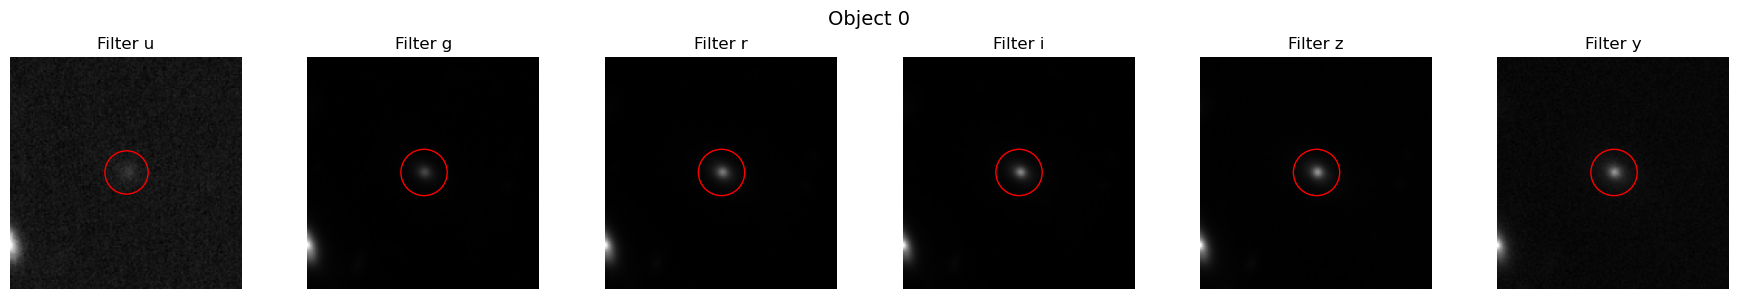

Galaxy's flux in filter u is 16.794 ± 0.028 mag
Galaxy's flux in filter g is 17.116 ± 0.006 mag
Galaxy's flux in filter r is 16.056 ± 0.004 mag
Galaxy's flux in filter i is 15.397 ± 0.003 mag
Galaxy's flux in filter z is 14.705 ± 0.003 mag
Galaxy's flux in filter y is 13.472 ± 0.005 mag


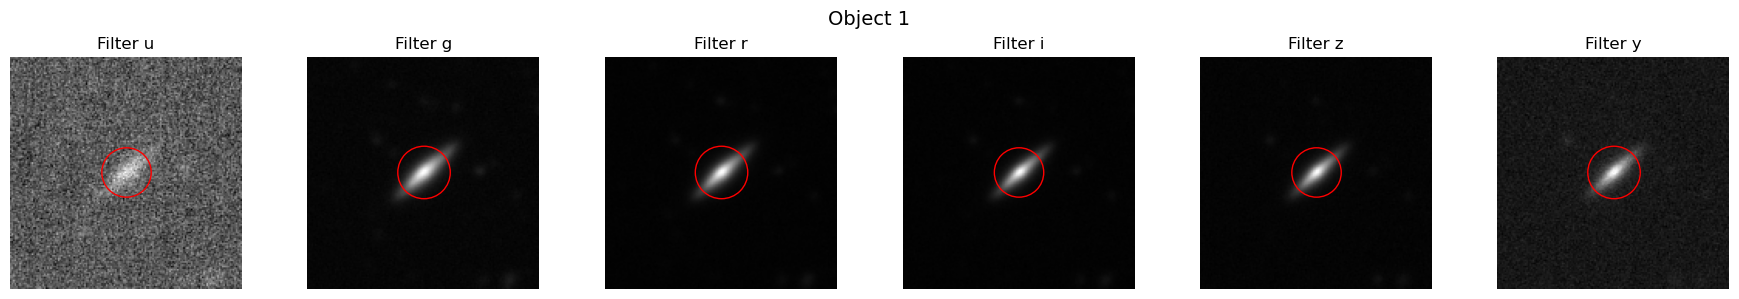

Galaxy's flux in filter u is 16.009 ± 0.013 mag
Galaxy's flux in filter g is 17.068 ± 0.006 mag
Galaxy's flux in filter r is 16.178 ± 0.004 mag
Galaxy's flux in filter i is 15.560 ± 0.003 mag
Galaxy's flux in filter z is 15.015 ± 0.003 mag
Galaxy's flux in filter y is 13.886 ± 0.006 mag


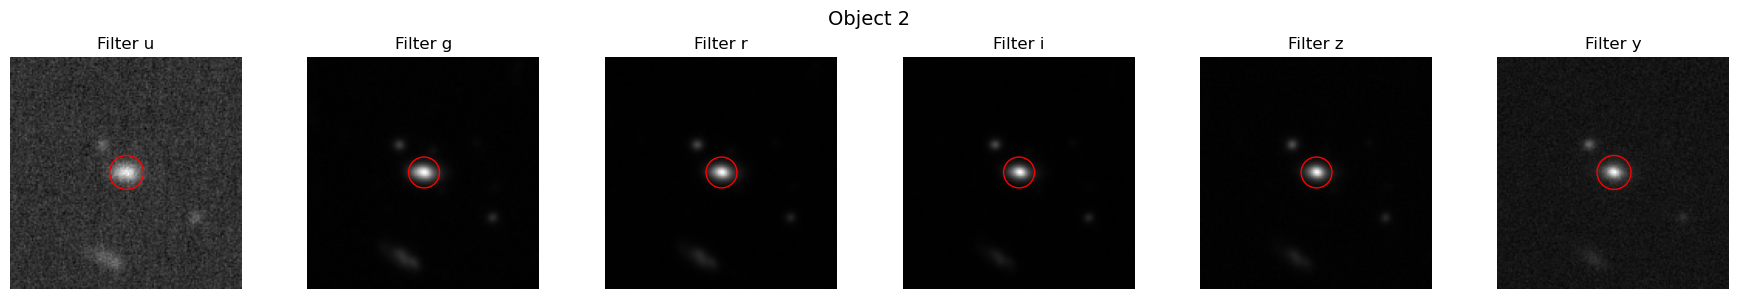

Galaxy's flux in filter u is 18.125 ± 0.064 mag
Galaxy's flux in filter g is 18.595 ± 0.012 mag
Galaxy's flux in filter r is 17.484 ± 0.007 mag
Galaxy's flux in filter i is 16.830 ± 0.006 mag
Galaxy's flux in filter z is 16.158 ± 0.006 mag
Galaxy's flux in filter y is 14.974 ± 0.014 mag


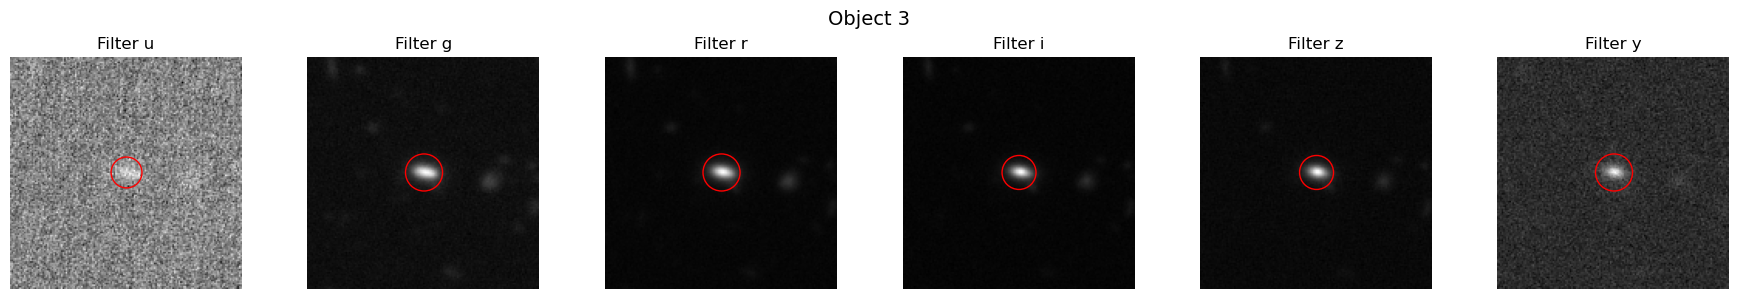

Galaxy's flux in filter u is 17.110 ± 0.032 mag
Galaxy's flux in filter g is 17.116 ± 0.006 mag
Galaxy's flux in filter r is 16.180 ± 0.004 mag
Galaxy's flux in filter i is 15.639 ± 0.003 mag
Galaxy's flux in filter z is 15.061 ± 0.003 mag
Galaxy's flux in filter y is 13.911 ± 0.007 mag


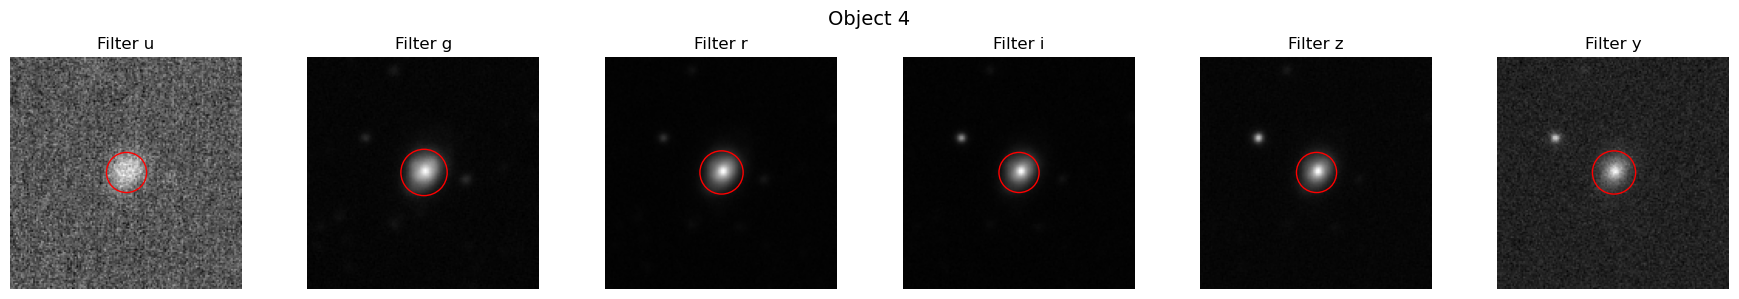

Galaxy's flux in filter u is 17.157 ± 0.051 mag
Galaxy's flux in filter g is 17.635 ± 0.007 mag
Galaxy's flux in filter r is 16.433 ± 0.004 mag
Galaxy's flux in filter i is 15.864 ± 0.004 mag
Galaxy's flux in filter z is 15.216 ± 0.003 mag
Galaxy's flux in filter y is 14.041 ± 0.007 mag


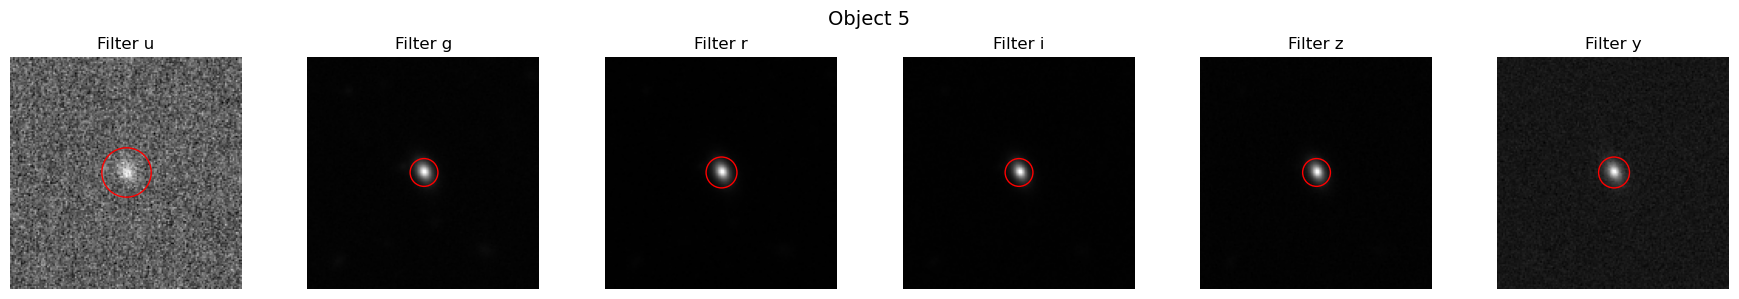

Galaxy's flux in filter u is 18.238 ± 0.130 mag
Galaxy's flux in filter g is 19.244 ± 0.016 mag
Galaxy's flux in filter r is 18.158 ± 0.010 mag
Galaxy's flux in filter i is 17.515 ± 0.009 mag
Galaxy's flux in filter z is 16.850 ± 0.008 mag
Galaxy's flux in filter y is 15.613 ± 0.031 mag


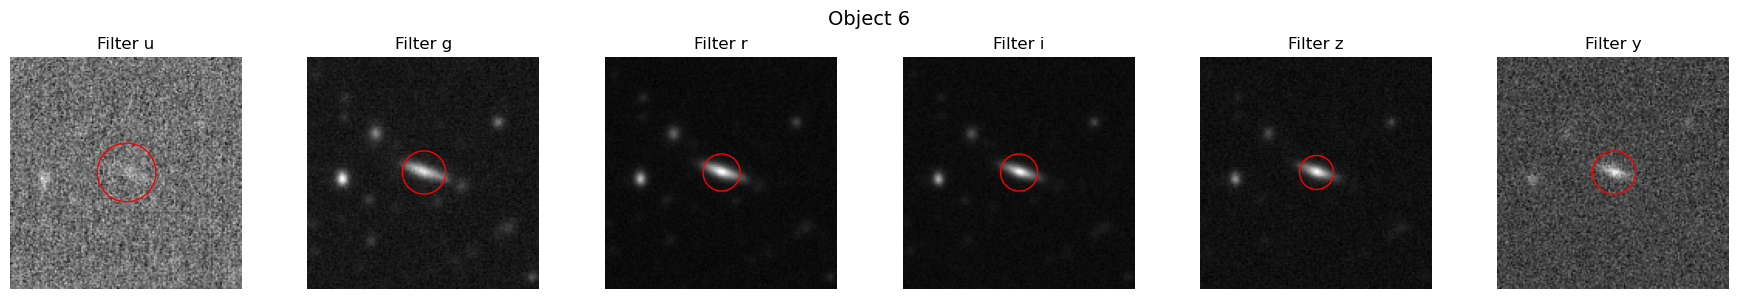

Galaxy's flux in filter u is 16.007 ± 0.016 mag
Galaxy's flux in filter g is 17.034 ± 0.006 mag
Galaxy's flux in filter r is 16.245 ± 0.004 mag
Galaxy's flux in filter i is 15.814 ± 0.004 mag
Galaxy's flux in filter z is 15.257 ± 0.004 mag
Galaxy's flux in filter y is 14.203 ± 0.009 mag


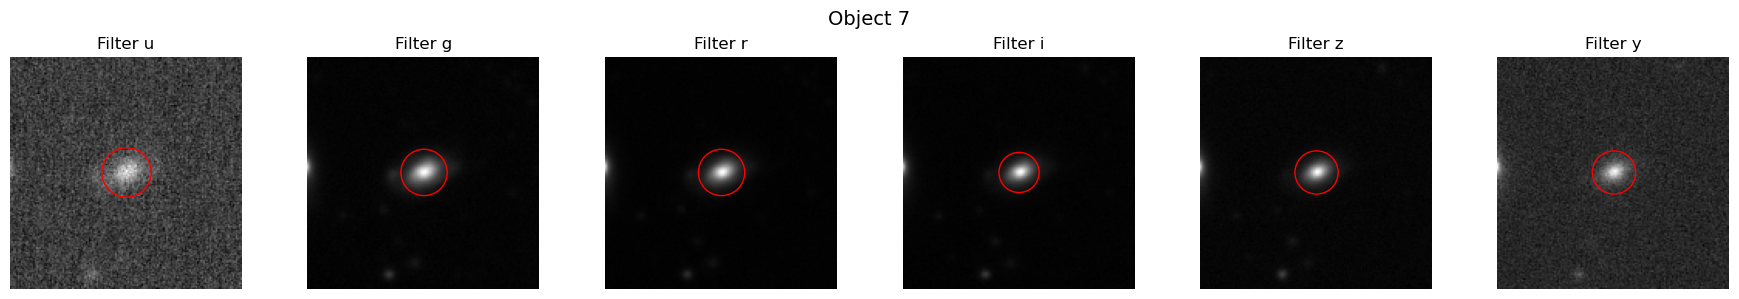

Galaxy's flux in filter u is 17.111 ± 0.039 mag
Galaxy's flux in filter g is 17.382 ± 0.007 mag
Galaxy's flux in filter r is 16.295 ± 0.004 mag
Galaxy's flux in filter i is 15.703 ± 0.004 mag
Galaxy's flux in filter z is 15.060 ± 0.003 mag
Galaxy's flux in filter y is 13.958 ± 0.007 mag


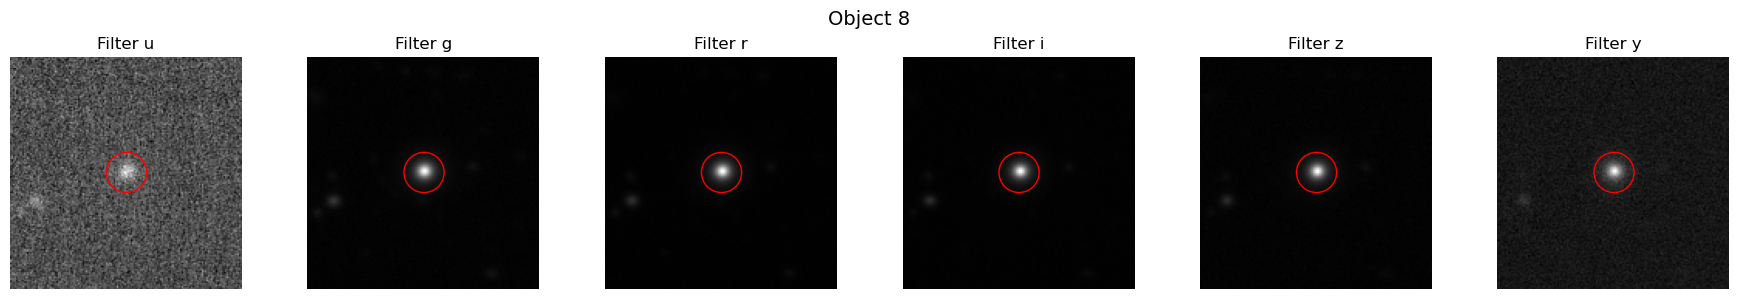

Galaxy's flux in filter u is 18.603 ± 0.064 mag
Galaxy's flux in filter g is 19.191 ± 0.015 mag
Galaxy's flux in filter r is 17.967 ± 0.009 mag
Galaxy's flux in filter i is 17.343 ± 0.008 mag
Galaxy's flux in filter z is 16.654 ± 0.007 mag
Galaxy's flux in filter y is 15.468 ± 0.022 mag


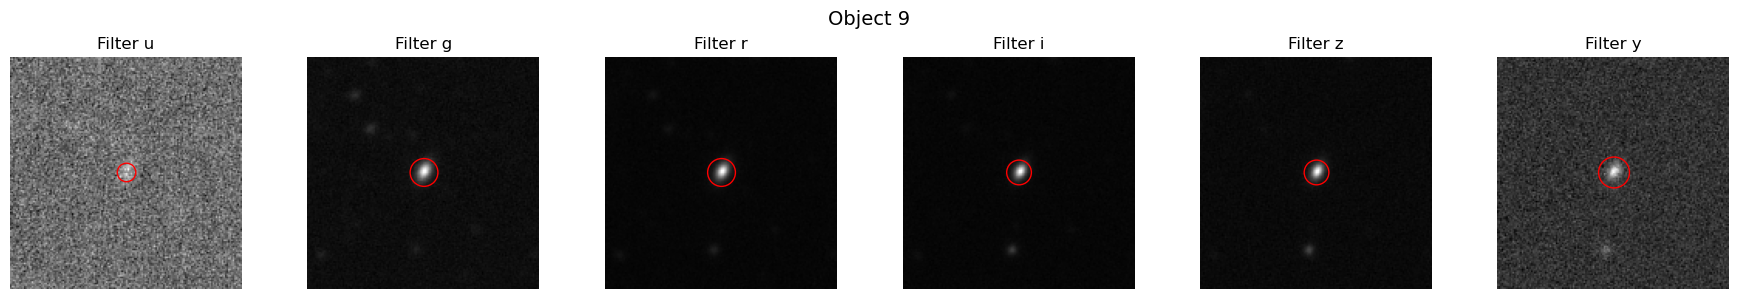

Galaxy's flux in filter u is 16.075 ± 0.014 mag
Galaxy's flux in filter g is 16.456 ± 0.004 mag
Galaxy's flux in filter r is 15.502 ± 0.003 mag
Galaxy's flux in filter i is 14.923 ± 0.002 mag
Galaxy's flux in filter z is 14.311 ± 0.002 mag
Galaxy's flux in filter y is 13.118 ± 0.004 mag


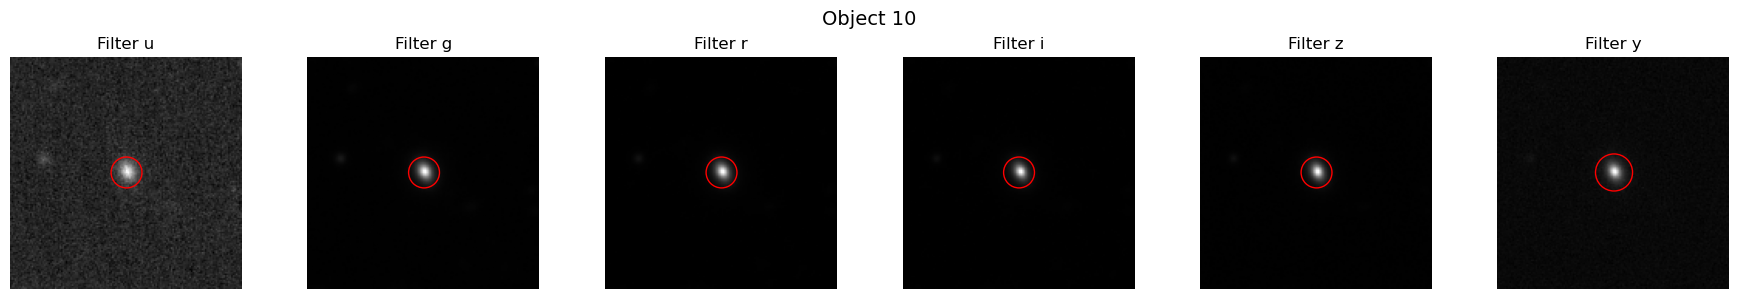

Galaxy's flux in filter u is 16.787 ± 0.023 mag
Galaxy's flux in filter g is 17.098 ± 0.006 mag
Galaxy's flux in filter r is 16.037 ± 0.004 mag
Galaxy's flux in filter i is 15.483 ± 0.003 mag
Galaxy's flux in filter z is 14.822 ± 0.003 mag
Galaxy's flux in filter y is 13.645 ± 0.006 mag


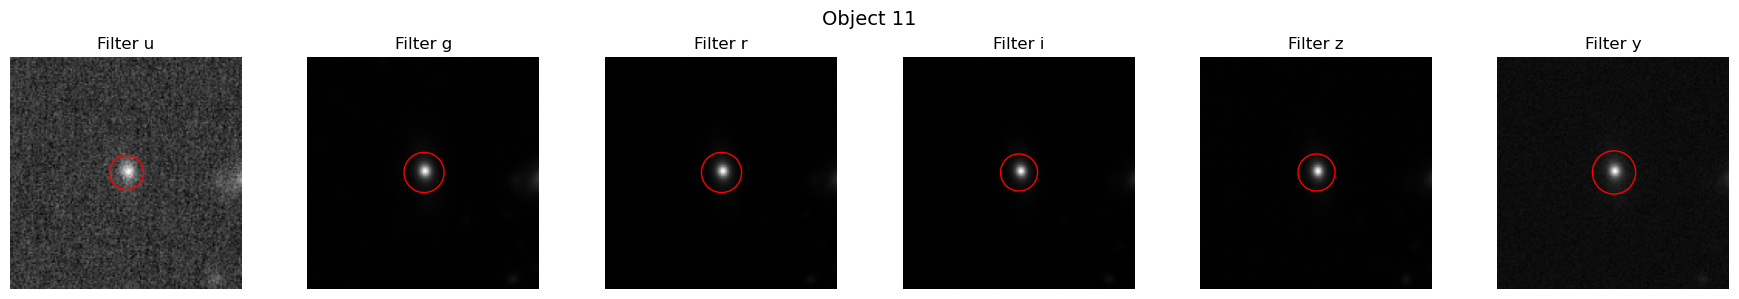

Galaxy's flux in filter u is 18.108 ± 0.076 mag
Galaxy's flux in filter g is 18.840 ± 0.013 mag
Galaxy's flux in filter r is 17.766 ± 0.008 mag
Galaxy's flux in filter i is 17.204 ± 0.007 mag
Galaxy's flux in filter z is 16.541 ± 0.007 mag
Galaxy's flux in filter y is 15.462 ± 0.014 mag


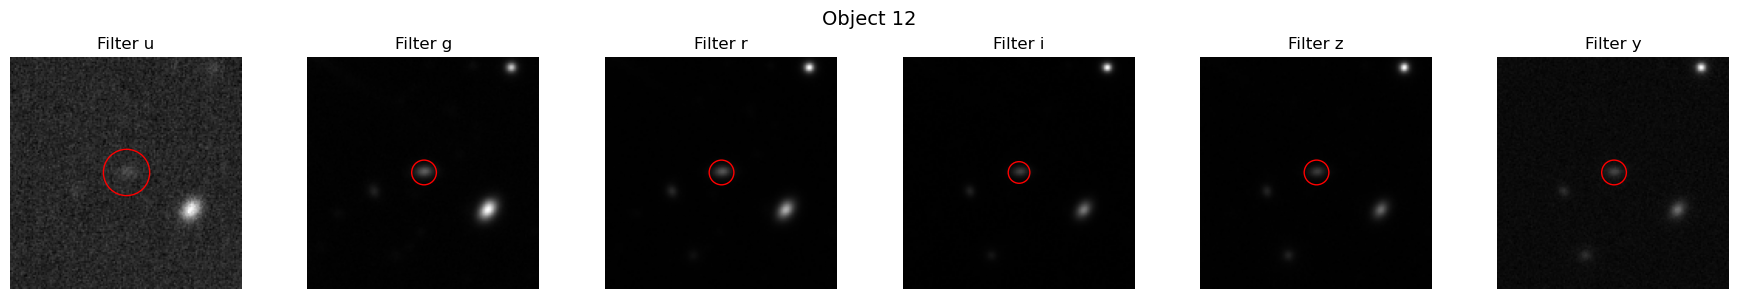

Galaxy's flux in filter u is 16.333 ± 0.019 mag
Galaxy's flux in filter g is 16.897 ± 0.005 mag
Galaxy's flux in filter r is 15.944 ± 0.004 mag
Galaxy's flux in filter i is 15.411 ± 0.003 mag
Galaxy's flux in filter z is 14.803 ± 0.003 mag
Galaxy's flux in filter y is 13.632 ± 0.006 mag


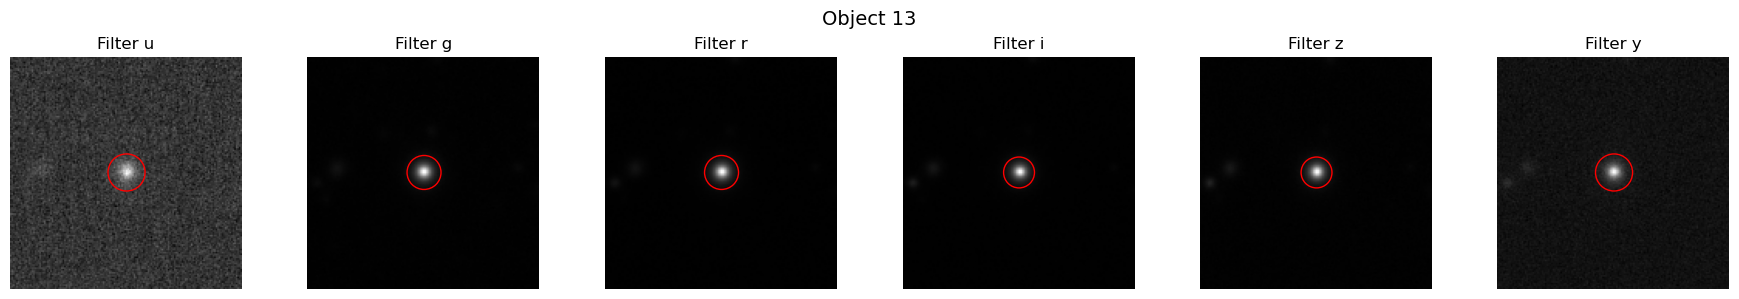

Galaxy's flux in filter u is 17.161 ± 0.039 mag
Galaxy's flux in filter g is 18.759 ± 0.012 mag
Galaxy's flux in filter r is 17.817 ± 0.009 mag
Galaxy's flux in filter i is 17.350 ± 0.008 mag
Galaxy's flux in filter z is 16.680 ± 0.007 mag
Galaxy's flux in filter y is 15.744 ± 0.020 mag


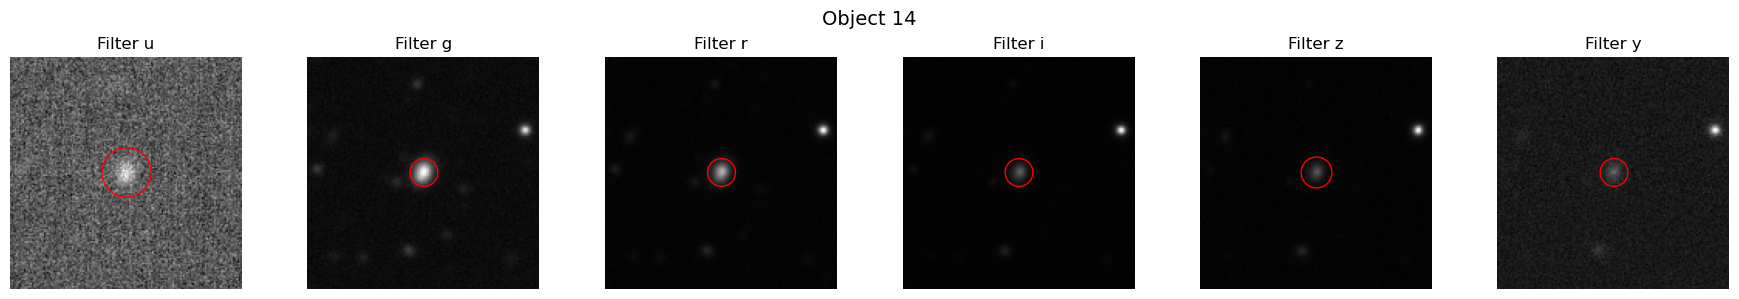

Galaxy's flux in filter u is 16.497 ± 0.021 mag
Galaxy's flux in filter g is 17.256 ± 0.006 mag
Galaxy's flux in filter r is 16.571 ± 0.005 mag
Galaxy's flux in filter i is 16.040 ± 0.004 mag
Galaxy's flux in filter z is 15.500 ± 0.004 mag
Galaxy's flux in filter y is 14.318 ± 0.010 mag


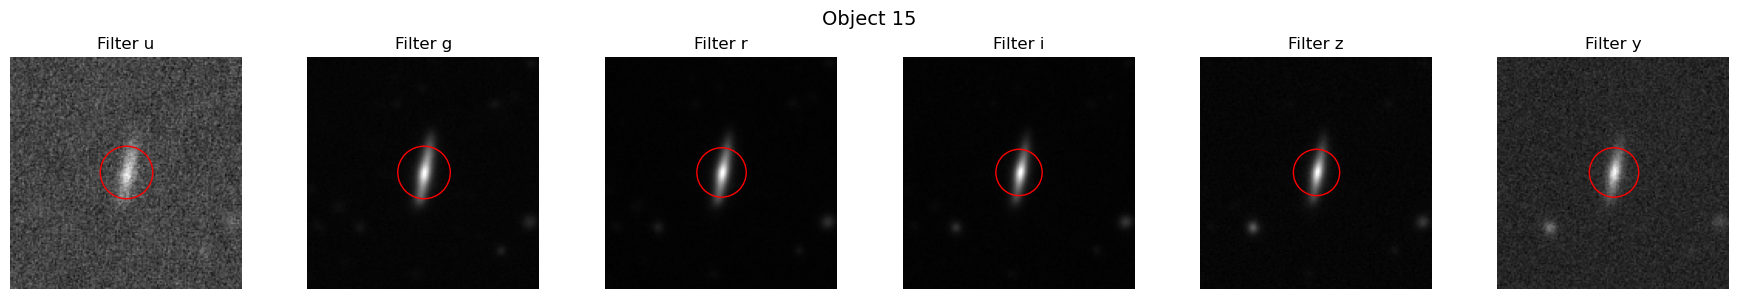

Galaxy's flux in filter u is 16.954 ± 0.023 mag
Galaxy's flux in filter g is 17.247 ± 0.006 mag
Galaxy's flux in filter r is 16.321 ± 0.004 mag
Galaxy's flux in filter i is 15.832 ± 0.004 mag
Galaxy's flux in filter z is 15.196 ± 0.003 mag
Galaxy's flux in filter y is 14.143 ± 0.008 mag


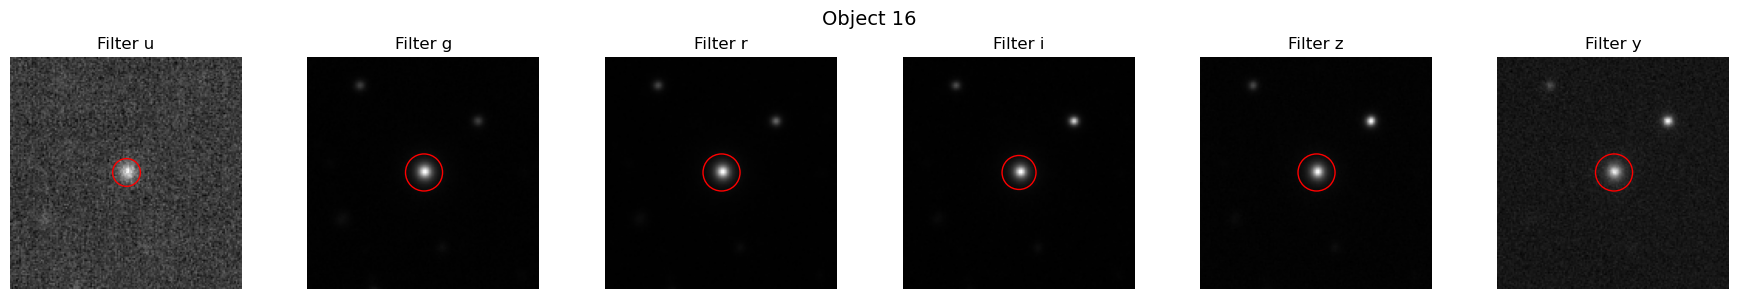

Galaxy's flux in filter u is 17.036 ± 0.023 mag
Galaxy's flux in filter g is 18.295 ± 0.010 mag
Galaxy's flux in filter r is 17.565 ± 0.008 mag
Galaxy's flux in filter i is 17.246 ± 0.007 mag
Galaxy's flux in filter z is 16.659 ± 0.007 mag
Galaxy's flux in filter y is 15.646 ± 0.018 mag


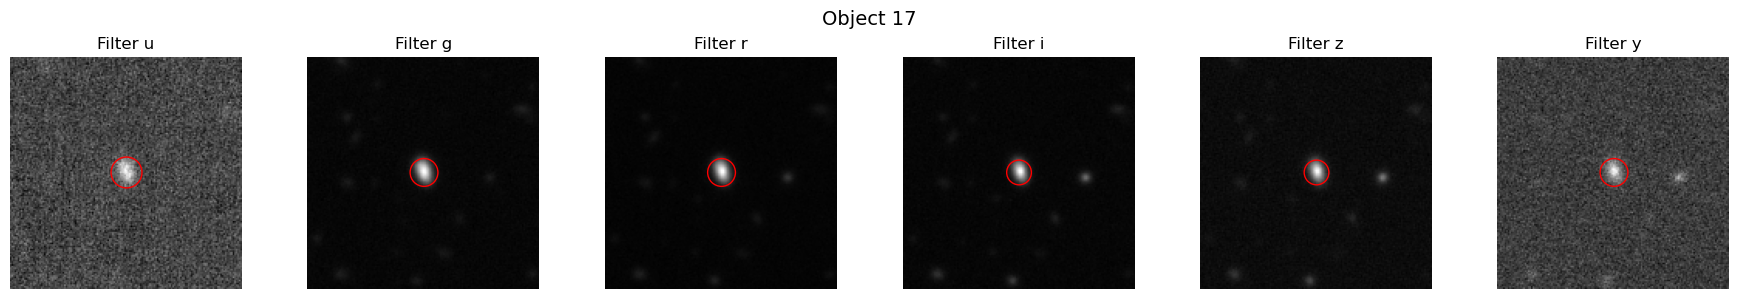

Galaxy's flux in filter u is 18.510 ± 0.068 mag
Galaxy's flux in filter g is 19.720 ± 0.020 mag
Galaxy's flux in filter r is 18.741 ± 0.013 mag
Galaxy's flux in filter i is 18.189 ± 0.012 mag
Galaxy's flux in filter z is 17.587 ± 0.012 mag
Galaxy's flux in filter y is 16.493 ± 0.037 mag


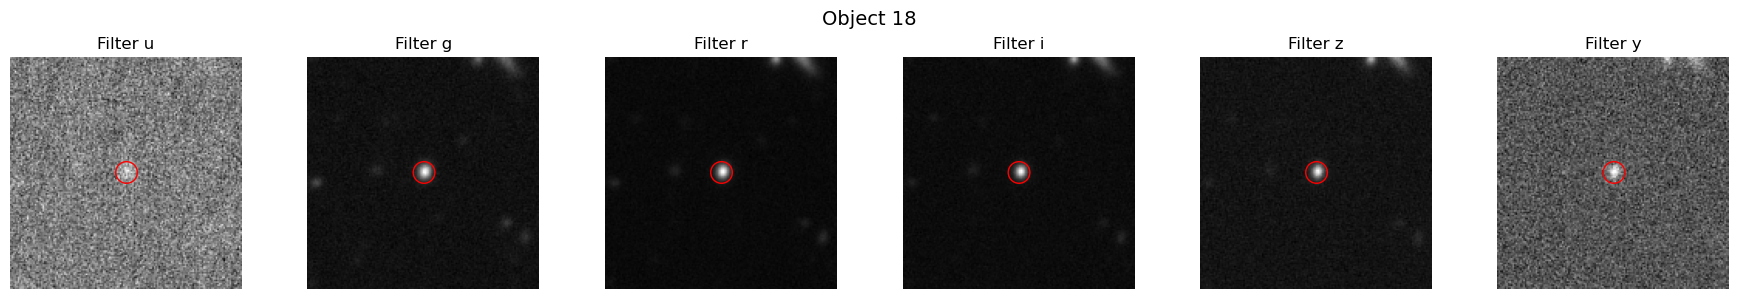

Galaxy's flux in filter u is 16.442 ± 0.019 mag
Galaxy's flux in filter g is 17.781 ± 0.008 mag
Galaxy's flux in filter r is 17.155 ± 0.006 mag
Galaxy's flux in filter i is 16.907 ± 0.006 mag
Galaxy's flux in filter z is 16.344 ± 0.006 mag
Galaxy's flux in filter y is 15.336 ± 0.024 mag


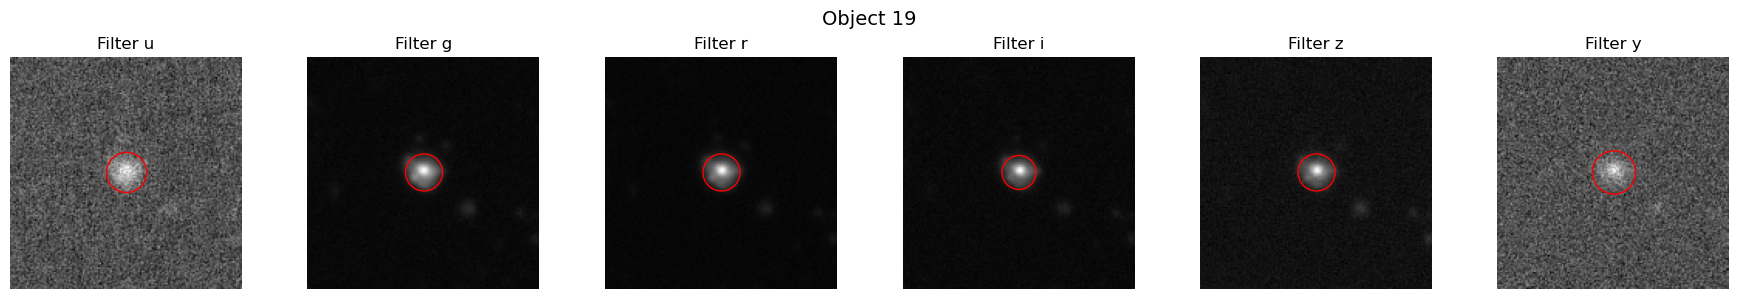

Galaxy's flux in filter u is 17.319 ± 0.030 mag
Galaxy's flux in filter g is 18.563 ± 0.011 mag
Galaxy's flux in filter r is 17.751 ± 0.008 mag
Galaxy's flux in filter i is 17.371 ± 0.008 mag


KeyboardInterrupt: 

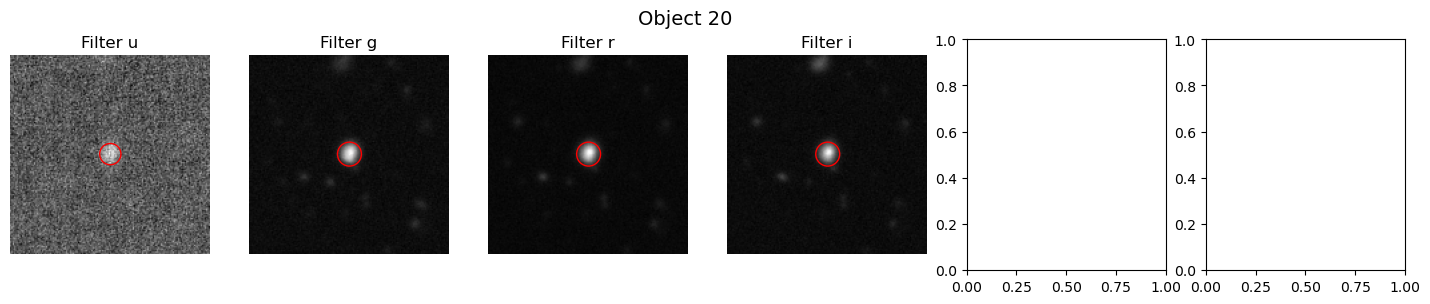

In [ ]:
def adu_to_mjy(counts_adu, zp_inst, gain=1.0):

    electrons = counts_adu * gain

    if hasattr(electrons, "nominal_value"):
        if electrons.nominal_value <= 0:
            return 0.0
    else:
        if electrons <= 0:
            return 0.0

    ab_mag = zp_inst - 2.5 * umath.log10(electrons)

    flux_jy = 3631 * 10**(-0.4 * ab_mag)

    return flux_jy * 1000

rcParams['figure.figsize'] = [10., 8.]

n_objects = 90
n_filters = 6

# Open FITS file
hdul = fits.open("galaxies_images.fits")

filter_names = ['u', 'g', 'r', 'i', 'z', 'y']

zp = [26.52, 28.51, 28.36, 28.17, 27.78, 26.82] # for gain = 1.0 from LSST page: https://smtn-002.lsst.io/

radius_range = 30

for obj in range(n_objects):

    fig, axes = plt.subplots(1, n_filters, figsize=(3 * n_filters, 3))
    fig.suptitle(f"Object {obj}", fontsize=14)

    for f in range(n_filters):

        i = obj * n_filters + f + 1
        image = hdul[i].data
        data = image.astype(image.dtype.newbyteorder('='))

        # Background substraction
        bkg = sep.Background(data)
        bkg_rms = bkg.rms()
        data = data - bkg

        gals = detect_sources(data)
        mask = make_mask(data, gals)

        # deleting objects
        data = np.where(mask, bkg.back(), data)

        ax = axes[f]
        im = ax.imshow(data, cmap="gray", origin="lower")
        ax.set_title(f"Filter {filter_names[f]}")
        ax.axis("off")

        # Getting different fluxes
        fluxes = unp.uarray(np.zeros(radius_range), np.zeros(radius_range))

        for j in range(radius_range):
            flux, fluxerr, flag = sep.sum_circle(data, x=[75.0], y=[75.0], 
                                                r=j, err=bkg.globalrms, gain=1.0)
            
            flux_with_err = unp.uarray(flux[0], fluxerr[0])
            flux_with_err = adu_to_mjy(flux_with_err, zp[f])

            fluxes[j] = flux_with_err\

        # Picking radius and calculating 
        max_flux = fluxes[radius_range - 1]
        flux80 = 0.8 * max_flux
        k = 0
        while (fluxes[k] < flux80):
            k = k + 1
        radius80 = k

        e = Circle([75.0, 75.0],radius80)
    
        e.set_facecolor('none')
        e.set_edgecolor('red')
        ax.add_artist(e)

        mag_with_err = ufloat(0, 0)

        if (radius80 == 0):
            print("No radius")
        else:
            if fluxes[radius80].nominal_value <= 0:
                print("Flux <= 0, cannot take log10")
            else:
                mag_with_err = 16.4 - 2.5 * unp.log10(fluxes[radius80])

                print(f"Galaxy's flux in filter {filter_names[f]} is {unp.nominal_values(mag_with_err):.3f} \u00B1 {unp.std_devs(mag_with_err):.3f} mag")

    plt.tight_layout()
    plt.show()
